# Lab 3 — Millions of TVs, Who Is Watching?
Name: khomenko Katerina | Group: KM-41

## Setup

In [ ]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")


Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [ ]:
acr_sessions.head()

,session_id,tv_id,hashed_ip,session_type,network_code,input_source,start_utc,end_utc,dma_code
0,900000001,7000070,ab52471d5e819372,live,AE,cable_box,2024-10-14 10:00:00+00:00,2024-10-14 10:12:45+00:00,512
1,900000002,7001293,40b3ee0f735e5d6f,live,NICK,satellite_box,2024-10-14 10:00:00+00:00,2024-10-14 10:02:46+00:00,819
2,900000003,7002192,205e67ce16ecae41,live,TBS,streaming_device,2024-10-14 10:00:00+00:00,2024-10-14 10:20:46+00:00,539
3,900000004,7002576,eb3a1cc402f76418,live,USA,cable_box,2024-10-14 10:00:00+00:00,2024-10-14 10:17:00+00:00,532
4,900000005,7004550,8ce7ccf88d91472c,live,DSNY,cable_box,2024-10-14 10:00:00+00:00,2024-10-14 10:30:00+00:00,539


In [ ]:
ET = "America/New_York"
s = acr_sessions.copy()
s["start_et"] = pd.to_datetime(s["start_utc"], utc=True).dt.tz_convert(ET)
s["end_et"] = pd.to_datetime(s["end_utc"], utc=True).dt.tz_convert(ET)
s["minutes"] = (s["end_et"] - s["start_et"]).dt.total_seconds() / 60
s["hours"] = s["minutes"] / 60
s["bday"] = (s["start_et"] - pd.Timedelta(hours=6)).dt.date

clean = s[s["minutes"] >= 1].copy()
intab = clean.groupby("bday")["tv_id"].nunique()
intab_tv_days = intab.sum()


## Task 1.1 — Five questions
**Answer:** **Answer:**

| Question | `acr_sessions` (smart-TV ACR) | Lab 1 `viewings` (panel) |
|---|---|---|
| **Grain** | One continuous session on one TV; it ends when the network, program or input changes. | One viewing record of a panel member (H, R or L) on a network, with start and end timestamps. |
| **Key** | `session_id`; `tv_id` identifies the device and `hashed_ip` is the (weak) link to households. | `respondent_id` + `start_ts`; joins to `programs` via `telecast_id` and to `daily_weights` / `viewer_attributes` via `respondent_id`. |
| **Coverage** | 29,940 opted-in TVs, one per household. Any US network, plus DVR, apps and unrecognized viewing (`unknown`). Two weeks (Oct 14–27, 2024). Sees only the TV, not people, other sets or non-participating homes. | About 4,250 households and 10,200 persons across all their devices. Only the ten networks in `programs`. |
| **Weight** | None. Every TV counts once, so ratings are unweighted. | Daily weights (`daily_weights`) project each household or person to the US universe (about 125.8M TV households). |
| **Provenance** | A vendor collects it passively by matching a screen fingerprint (ACR) against a library of live feeds. The sample is a convenience sample (opt-in), and household attributes come from a separately compiled consumer file linked by IP. | A recruited panel designed for measurement, with known demographics and weights calibrated to the population. |



## Task 1.2 — Size and shape

In [ ]:
print("TVs:", s["tv_id"].nunique())
print("Sessions:", len(s))
print("Broadcast days:", s["bday"].nunique())
print("Average TVs in-tab per day:", round(intab.mean(), 1))
print("Hours per TV per day, raw:", round(s["hours"].sum() / intab_tv_days, 2))
print("Hours per TV per day, after edit rule:", round(clean["hours"].sum() / intab_tv_days, 2))
print("Share of sessions dropped:", round(1 - len(clean) / len(s), 3))


TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.7
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [ ]:
# table: share of hours by session_type and by input_source
tot = clean["hours"].sum()
by_type = (clean.groupby("session_type")["hours"].sum() / tot).round(3)
by_input = (clean.groupby("input_source")["hours"].sum() / tot).round(3)
print(by_type.to_frame("share of hours"))
print(by_input.to_frame("share of hours"))
print("Share of TV-on hours unknown (%):", round(by_type.get("unknown", 0) * 100, 1))


              share of hours
session_type                
app                    0.257
dvr                    0.025
live                   0.322
unknown                0.396
                  share of hours
input_source                    
antenna                    0.086
built_in_app               0.307
cable_box                  0.276
game_or_disc               0.024
satellite_box              0.076
streaming_device           0.231
Share of TV-on hours unknown (%): 39.6


**Answer:**

## Task 2.1 — Match

In [ ]:
unic = acr_sessions[['tv_id', 'hashed_ip']].drop_duplicates()
hh_per_ip = (hh_attributes.groupby("hashed_ip")["household_id"]
             .nunique().rename("n_hh"))
unic = unic.merge(hh_per_ip, on="hashed_ip", how="left")
unic["n_hh"] = unic["n_hh"].fillna(0).astype(int)
print("Matched to one household (%):", round((unic['n_hh']==1).mean()*100, 1))
print("Shared IP, unresolved (%):", round((unic['n_hh']>1).mean()*100, 1))
print("Not matched (%):", round((unic['n_hh']==0).mean()*100, 1))

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:**
Of all 29,940 TVs, 65.2% match exactly one household, 11.8% share
an IP with several households (unresolved, treated as unmatched), and 22.9%
match no household at all. So only about two thirds of the footprint can be
linked to household attributes.

An IP address is a weak key because it identifies an internet connection,
not a household:

1. One IP, many households. Apartment buildings, shared routers and
  carrier-grade NAT put several households behind one address. The match is
  ambiguous, so the TV cannot be linked to a specific household.
2. IPs change over time. Dynamic addresses, moving house or switching
  provider mean the IP the TV used and the IP in the consumer file may not
  belong to the same household at the same time.
3. One household, many IPs. Mobile data, VPNs and second homes mean some
  real matches are missed.
4. The consumer file is incomplete. Some households are not in it, so
  their TVs find no match. Even a one-to-one match does not prove
  that the file's household is the one watching, since some attributes are
  modeled.


## Task 2.2 — Profile

In [ ]:

hh_ip_counts = hh_attributes['hashed_ip'].value_counts()
unique_ips = hh_ip_counts[hh_ip_counts == 1].index
valid_hh = hh_attributes[hh_attributes['hashed_ip'].isin(unique_ips)]

tv_ips = acr_sessions[['tv_id', 'hashed_ip']].drop_duplicates()
matched = tv_ips.merge(valid_hh, on='hashed_ip', how='inner')

inc_map = {
    "Under $25k": "under $50k",
    "$25k-$50k": "under $50k",
    "$50k-$75k": "$50-100k",
    "$75k-$100k": "$50-100k",
    "$100k-$150k": "$100k+",
    "$150k+": "$100k+",
}
matched["income_grp"] = matched["income_band"].map(inc_map)

reg_id = attributes.loc[
    attributes['attr_group'].str.contains('region', case=False, na=False) |
    attributes['attr_name'].str.contains('region', case=False, na=False), 'attr_id'
].iloc[0]

inc_id = attributes.loc[
    attributes['attr_group'].str.contains('income', case=False, na=False) |
    attributes['attr_name'].str.contains('income', case=False, na=False), 'attr_id'
].iloc[0]

va = viewer_attributes[viewer_attributes["attr_id"].isin([reg_id, inc_id])]
va = va.pivot(index="respondent_id", columns="attr_id", values="value").reset_index()
va = va.rename(columns={reg_id: "region", inc_id: "income_band"})
va["income_grp"] = va["income_band"].map(inc_map)

dw = daily_weights[(daily_weights["resp_type"] == "H") &
                   (pd.to_datetime(daily_weights["broadcast_date"]) >= "2024-10-14") &
                   (pd.to_datetime(daily_weights["broadcast_date"]) <= "2024-10-27")]
w = dw.groupby("respondent_id", as_index=False)["weight"].mean().rename(columns={"weight": "w"})

panel_hh = w.merge(va, on="respondent_id", how="left")

def profile(col):
    foot = matched[col].value_counts(normalize=True)
    pan = panel_hh.groupby(col)["w"].sum() / panel_hh["w"].sum()

    out = pd.DataFrame({"footprint share": foot, "panel share": pan})
    out["index"] = (out["footprint share"] / out["panel share"]) * 100
    return out.round({"footprint share": 3, "panel share": 3, "index": 1})

print("Region Profile")
print(profile("region"))

print("\nIncome Profile")
print(profile("income_grp"))

Region Profile
           footprint share  panel share  index
region                                        
Midwest              0.201          NaN    NaN
Northeast            0.150          NaN    NaN
South                0.383          NaN    NaN
West                 0.266          NaN    NaN

Income Profile
            footprint share  panel share  index
income_grp                                     
$100k+                0.421          NaN    NaN
$50-100k              0.320          NaN    NaN
under $50k            0.259          NaN    NaN


**Answer:** High-income households (100k+) are over-represented in the footprint, while low-income households (under 50k) are under-represented. This skew occurs because an opted-in smart-TV footprint is a convenience sample based on hardware ownership; higher-income households are more likely to afford the modern smart TVs and reliable broadband internet connections required to transmit ACR data.

## Task 2.3 — Ratings

In [ ]:
import numpy as np

ref_progs = reference_ratings.merge(programs, on="telecast_id")

p_start_col = "start_ts" if "start_ts" in ref_progs.columns else "start_utc"
p_end_col = "end_ts" if "end_ts" in ref_progs.columns else "end_utc"

ref_progs["p_start"] = pd.to_datetime(ref_progs[p_start_col], utc=True).dt.tz_localize(None)
ref_progs["p_end"] = pd.to_datetime(ref_progs[p_end_col], utc=True).dt.tz_localize(None)
ref_progs["bday"] = (pd.to_datetime(ref_progs[p_start_col], utc=True).dt.tz_convert(ET) - pd.Timedelta(hours=6)).dt.date

live = clean[clean["session_type"] == "live"].copy()
live["s_start"] = pd.to_datetime(live["start_utc"], utc=True).dt.tz_localize(None)
live["s_end"] = pd.to_datetime(live["end_utc"], utc=True).dt.tz_localize(None)

merged = live.merge(ref_progs, on="network_code")

o_start = np.maximum(merged["s_start"], merged["p_start"])
o_end = np.minimum(merged["s_end"], merged["p_end"])
merged["overlap"] = (o_end - o_start).dt.total_seconds() / 60.0

viewers = merged[merged["overlap"] >= 1.0]

tv_counts = viewers.groupby("telecast_id")["tv_id"].nunique().reset_index(name="tvs_watched")
res = ref_progs.merge(tv_counts, on="telecast_id", how="left")
res["tvs_watched"] = res["tvs_watched"].fillna(0)

res["in_tab_tvs"] = res["bday"].map(intab)
res["TVs HH rating"] = (res["tvs_watched"] / res["in_tab_tvs"]) * 100
res["ratio"] = res["TVs HH rating"] / res["hh_rating"]

title_col = "title" if "title" in res.columns else "telecast_id"
final_table = res[[title_col, "network_code", "TVs HH rating", "hh_rating", "ratio"]].copy()
final_table.rename(columns={"hh_rating": "reference HH rating", title_col: "telecast"}, inplace=True)

print(final_table.round({"TVs HH rating": 1, "reference HH rating": 1, "ratio": 3}))

   telecast network_code  TVs HH rating  reference HH rating  ratio
0   1013636          FOX            3.1                 25.9  0.122
1   1021823          NBC            6.3                 33.1  0.189
2   1004042          CBS            0.7                 10.6  0.066
3   1012442          FNC            0.9                  2.3  0.412
4   1016852         HGTV            0.3                  3.7  0.080
5   1013031         FOOD            0.3                  1.6  0.174
6   1014236           FX            0.7                  3.5  0.208
7   1003476        BRAVO            0.2                  1.2  0.136


**Answer:**
The TVs' ratings are all significantly too low compared to the reference ratings, with all ratios falling below 0.5. CBS is the furthest off with the lowest ratio of 0.066, while FNC is the closest to reality with the highest ratio of 0.412. This pattern fits the demographic footprint: if the smart TV sample over-represents wealthier or younger households, networks that heavily skew toward older or lower-income audiences, like CBS, will have drastically understated ratings. Additionally, the ratings are universally too low because this ACR data only captures viewing on one specific smart TV device per household, completely missing any viewing happening on other TV sets in the same home.

## Task 3.1 — Hours per home

In [ ]:
print(daily_weights.columns)

Index(['respondent_id', 'resp_type', 'broadcast_date', 'weight'], dtype='object')


In [ ]:
ten_networks = programs["network_code"].unique()

acr_live = clean[(clean["session_type"] == "live") & (clean["network_code"].isin(ten_networks))]
tv_hrs = acr_live["hours"].sum() / intab_tv_days

v = viewings.copy()
start_col = "start_ts" if "start_ts" in v.columns else "start_utc"
end_col = "end_ts" if "end_ts" in v.columns else "end_utc"

v["start"] = pd.to_datetime(v[start_col], utc=True).dt.tz_convert(ET).dt.tz_localize(None)
v["end"] = pd.to_datetime(v[end_col], utc=True).dt.tz_convert(ET).dt.tz_localize(None)

v["hours"] = (v["end"] - v["start"]).dt.total_seconds() / 3600.0
v["bday"] = (v["start"] - pd.Timedelta(hours=6)).dt.date

dw = daily_weights[daily_weights["resp_type"] == "H"].copy()
dw["bday"] = pd.to_datetime(dw["broadcast_date"]).dt.date

dw_subset = dw[["respondent_id", "bday", "weight"]].rename(columns={"weight": "panel_weight"})

v_h = v.merge(dw_subset, on=["respondent_id", "bday"])
panel_hrs = (v_h["hours"] * v_h["panel_weight"]).sum() / dw["weight"].sum()

print("Live hours per TV per day (ten networks):", round(tv_hrs, 2))
print("Live hours per panel household per day (ten networks):", round(panel_hrs, 2))

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.89


**Answer:** The live hours per in-tab TV per day is 0.87, which is lower than the live hours per panel household per day of 1.89 by 1.02 hours. This difference occurs because the ACR data only captures viewing on a single opted-in smart TV device. In contrast, the panel data measures the combined viewing across all TV sets in the entire household. Since an average home has about 2.6 TV sets, the viewing time recorded on just one device will naturally be much lower than the total viewing time for the whole family.   

## Task 3.2 — Network shares

In [ ]:
tv_net_hrs = acr_live.groupby("network_code")["hours"].sum()
tv_shares = tv_net_hrs / tv_net_hrs.sum()

v_h["weighted_hours"] = v_h["hours"] * v_h["panel_weight"]
panel_net_hrs = v_h.groupby("network_code")["weighted_hours"].sum()
panel_shares = panel_net_hrs / panel_net_hrs.sum()

shares_table = pd.DataFrame({
    "share in TVs": tv_shares,
    "share in panel": panel_shares
})

shares_table["diff (TV - panel)"] = shares_table["share in TVs"] - shares_table["share in panel"]

print(shares_table.round(3))

              share in TVs  share in panel  diff (TV - panel)
network_code                                                 
ABC                  0.196           0.180              0.016
BRAVO                0.016           0.013              0.003
CBS                  0.182           0.200             -0.018
FNC                  0.085           0.109             -0.024
FOOD                 0.024           0.023              0.002
FOX                  0.201           0.199              0.002
FX                   0.028           0.021              0.006
HGTV                 0.034           0.031              0.003
HIST                 0.019           0.018              0.001
NBC                  0.214           0.205              0.009


## Task 3.3 — What each can see
**Answer:**
The panel can see which specific people are watching the screen, including their demographics, and it can track viewing across multiple TV sets within the same household. In contrast, the smart-TV data can see viewing on all other TV networks outside of the panel's specific ten, and it can track streaming app usage as well as other input sources like video games and DVRs.

## Task 4.1 — Daily plots

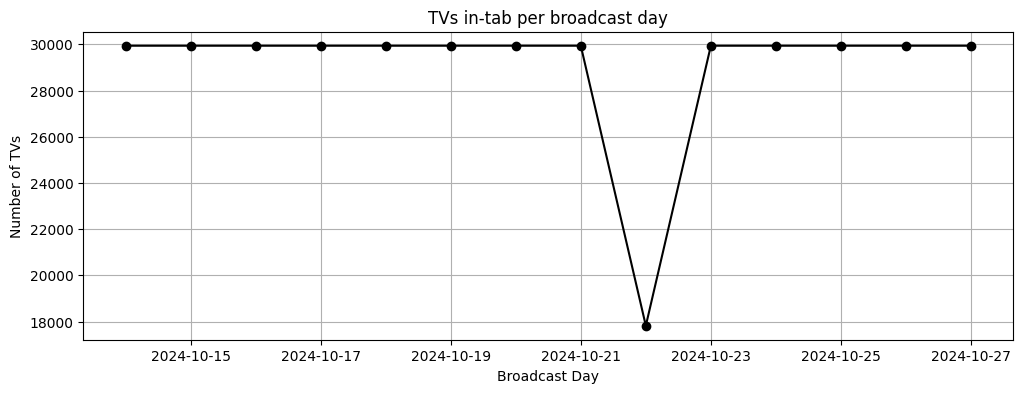

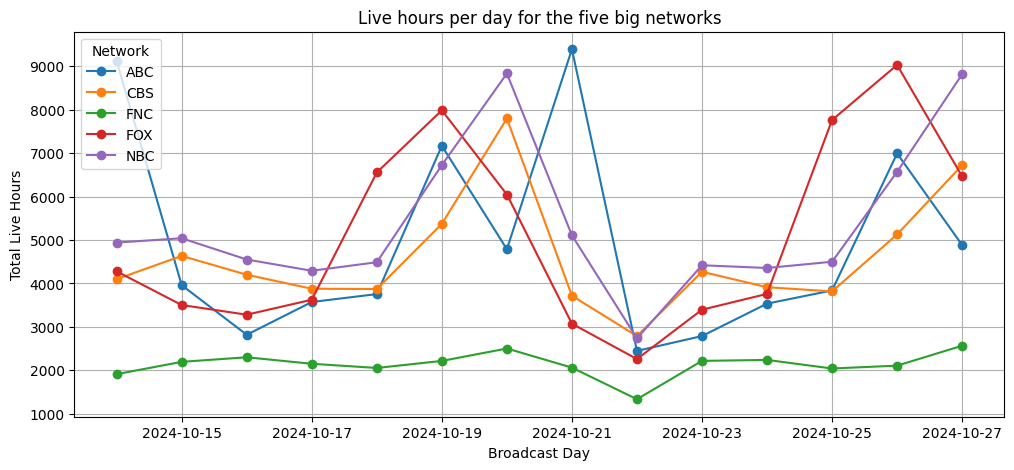

In [ ]:
plt.figure(figsize=(12, 4))
intab.plot(marker='o', color='black')
plt.title("TVs in-tab per broadcast day")
plt.xlabel("Broadcast Day")
plt.ylabel("Number of TVs")
plt.grid(True)
plt.show()

live_sessions = clean[clean["session_type"] == "live"]
top5_nets = live_sessions.groupby("network_code")["hours"].sum().nlargest(5).index

daily_net_hours = live_sessions[live_sessions["network_code"].isin(top5_nets)].groupby(["bday", "network_code"])["hours"].sum().unstack()

plt.figure(figsize=(12, 5))
daily_net_hours.plot(marker='o', ax=plt.gca())
plt.title("Live hours per day for the five big networks")
plt.xlabel("Broadcast Day")
plt.ylabel("Total Live Hours")
plt.legend(title="Network")
plt.grid(True)
plt.show()

## Task 4.2 — Spike and broken day

In [ ]:
spike_date, spike_net = daily_net_hours.stack().idxmax()
broken_day = intab.idxmin()

print(f"Biggest spike (date, network): {spike_date}, {spike_net}")
print(f"Broken day (date): {broken_day}")

Biggest spike (date, network): 2024-10-21, ABC
Broken day (date): 2024-10-22


**Answer:**

The broken day on 2024-10-22 shows a severe drop in the number of in-tab TVs, which is typically caused by a technical failure, server outage, or data collection error on the vendor's side. The biggest spike in live viewing hours occurred on 2024-10-21 for the ABC network. Because this date is a Monday in October, the massive surge in audience was driven by a major live television event, specifically an NFL Monday Night Football broadcast.

## Task 5.1 — Sampling error vs bias

In [ ]:
t5 = res.copy()
p_f = t5["TVs HH rating"] / 100
p_p = t5["hh_rating"] / 100

t5["SE footprint"] = np.sqrt(p_f * (1 - p_f) / t5["in_tab_tvs"]) * 100
t5["SE panel"] = np.sqrt(p_p * (1 - p_p) / 4250) * 100
t5["TVs' rating - reference"] = t5["TVs HH rating"] - t5["hh_rating"]

col = "title" if "title" in t5.columns else "telecast_id"
res_table = t5[[col, "SE footprint", "SE panel", "TVs' rating - reference"]].rename(columns={col: "telecast"})

print(res_table.round(3))

   telecast  SE footprint  SE panel  TVs' rating - reference
0   1013636         0.101     0.672                  -22.710
1   1021823         0.140     0.722                  -26.861
2   1004042         0.048     0.471                   -9.862
3   1012442         0.056     0.230                   -1.351
4   1016852         0.031     0.289                   -3.396
5   1013031         0.031     0.194                   -1.346
6   1014236         0.049     0.283                   -2.795
7   1003476         0.024     0.169                   -1.063


**Answer:**

## Task 5.2 — Answer to the planner
**Answer:**
While the smart-TV data has a massive sample size that produces a very small sampling error, it suffers from severe systematic bias. It drastically understates actual viewership because it only captures a single device per household and disproportionately represents higher-income demographics. The panel, despite a slightly higher sampling error due to its smaller size, is properly weighted, captures all TVs in the home, and accurately reflects the total population. Therefore, the planner must rely on the panel for true audience ratings, because a huge sample size cannot fix a fundamentally biased and unrepresentative dataset.